# Problema 4 — Classificação de risco de crédito com árvore

## Tarefa 1 — Dados, codificação e classes

Identificamos os atributos numéricos e categóricos, verificamos ausentes e examinamos o balanceamento das classes. Usamos one-hot para representar as categorias sem impor uma ordem artificial.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12

In [2]:
colunas = [
    'checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount',
    'savings_status', 'employment', 'installment_rate', 'personal_status',
    'other_parties', 'residence_since', 'property_magnitude', 'age',
    'other_payment_plans', 'housing', 'existing_credits', 'job',
    'num_dependents', 'own_telephone', 'foreign_worker', 'class'
]

df = pd.read_csv(
    "./data/statlog+german+credit+data/german.data",
    sep=' ',
    header=None,
    names=colunas
)

df.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [3]:
print("Valores ausentes por coluna:")
print(df.isnull().sum())

print("\nDuplicatas exatas encontradas:", df.duplicated().sum())

Valores ausentes por coluna:
checking_status        0
duration               0
credit_history         0
purpose                0
credit_amount          0
savings_status         0
employment             0
installment_rate       0
personal_status        0
other_parties          0
residence_since        0
property_magnitude     0
age                    0
other_payment_plans    0
housing                0
existing_credits       0
job                    0
num_dependents         0
own_telephone          0
foreign_worker         0
class                  0
dtype: int64

Duplicatas exatas encontradas: 0


In [4]:
df['class_desc'] = df['class'].map({1: 'bom', 2: 'mau'})

ordem_classes = ['bom', 'mau']
contagem_classes = df['class_desc'].value_counts()
proporcao_classes = (df['class_desc'].value_counts(normalize=True) * 100).round(2)

tabela_dist = pd.DataFrame({
    'Classe': ordem_classes,
    'Quantidade': [contagem_classes['bom'], contagem_classes['mau']],
    'Proporção (%)': [proporcao_classes['bom'], proporcao_classes['mau']]
})
display(tabela_dist)

,Classe,Quantidade,Proporção (%)
0,bom,700,70.0
1,mau,300,30.0


In [5]:
cat_cols = list(df.select_dtypes(include=['object']).columns.drop('class_desc'))
num_cols = list(df.select_dtypes(include=['int64']).columns.drop('class'))

print(f"Total de atributos numéricos ({len(num_cols)}): {num_cols}")
print(f"Total de atributos categóricos ({len(cat_cols)}): {cat_cols}")

# Aplicando One-Hot Encoding com drop_first=True para evitar redundância
X = pd.get_dummies(df.drop(columns=['class', 'class_desc']), drop_first=True)
y = df['class_desc']

print(f"\nDimensões da matriz de features após One-Hot Encoding: {X.shape[0]} amostras e {X.shape[1]} colunas binárias/numéricas")

Total de atributos numéricos (7): ['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'num_dependents']
Total de atributos categóricos (13): ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']

Dimensões da matriz de features após One-Hot Encoding: 1000 amostras e 48 colunas binárias/numéricas


### Preparação

- **Base:** 1.000 solicitações, sem valores ausentes.
- **Entradas:** sete atributos numéricos e 13 categóricos, listados no código.
- **Codificação:** cada categoria representada torna-se um indicador binário.

### Balanceamento

| Classe | Amostras | Proporção |
|---|---:|---:|
| Bom risco | 700 | 70% |
| Mau risco | 300 | 30% |

Prever sempre bom já produziria **70% de acurácia**, mesmo sem detectar nenhum mau risco. Por isso, também examinamos recall e F1 de cada classe.

## Tarefa 2 — Necessidade de normalização

Árvores de decisão comparam os valores de cada atributo com limiares. A escolha desses cortes depende da ordem dos valores.

**A padronização não é necessária.** Converter um atributo para outra escala linear crescente preserva sua ordem e os grupos formados pelos cortes.

A codificação categórica continua necessária para representar as categorias numericamente; ela cumpre uma função diferente da padronização.

## Tarefa 3 — Divisão treino/teste

Separamos 80% para treino e 20% para teste, com semente 42 e estratificação. A profundidade será escolhida usando apenas o treino.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Amostras de Treino: {X_train.shape[0]}")
print(f"Amostras de Teste:  {X_test.shape[0]}")

df_split = pd.DataFrame({
    'Treino (%)': (y_train.value_counts(normalize=True) * 100).round(2),
    'Teste (%)': (y_test.value_counts(normalize=True) * 100).round(2),
    'Treino (N)': y_train.value_counts(),
    'Teste (N)': y_test.value_counts()
})
display(df_split)

Amostras de Treino: 800
Amostras de Teste:  200


,Treino (%),Teste (%),Treino (N),Teste (N)
class_desc,,,,
bom,70.0,70.0,560,140
mau,30.0,30.0,240,60


| Conjunto | Bom risco | Mau risco | Total |
|---|---:|---:|---:|
| Treino | 560 | 240 | **800** |
| Teste | 140 | 60 | **200** |

A proporção **70%/30%** foi mantida nos dois conjuntos. O teste permanece reservado para a avaliação final.

## Tarefa 4 — Profundidade e critério

Comparamos profundidades **2, 3, 5, 7, 10 e sem limite** em cinco folds estratificados do treino. Repetimos o experimento com Gini e entropia; cada gráfico reúne as acurácias de treino e validação.

In [7]:
depth_values = [2, 3, 5, 7, 10, None]
depth_labels = ['2', '3', '5', '7', '10', 'Sem Limite']

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados_tuning = []

for criterion in ['gini', 'entropy']:
    for d, d_lbl in zip(depth_values, depth_labels):
        clf = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=d,
            random_state=42
        )
        scores = cross_validate(clf, X_train, y_train, cv=cv, scoring='accuracy', return_train_score=True)
        resultados_tuning.append({
            'Critério': criterion,
            'Profundidade': d_lbl,
            'max_depth_val': d if d is not None else 15,
            'Acurácia Treino': scores['train_score'].mean(),
            'Acurácia Validação': scores['test_score'].mean()
        })

df_tuning = pd.DataFrame(resultados_tuning)
display(df_tuning.pivot(index='Profundidade', columns='Critério', values=['Acurácia Treino', 'Acurácia Validação']).round(4))

Acurácia Treino         Acurácia Validação        
Critério             entropy    gini            entropy    gini
Profundidade                                                   
10                    0.9109  0.9328             0.7088  0.6662
2                     0.7069  0.7081             0.6938  0.6888
3                     0.7322  0.7369             0.6988  0.6975
5                     0.7853  0.7953             0.7137  0.7012
7                     0.8447  0.8600             0.7000  0.6900
Sem Limite            1.0000  1.0000             0.7088  0.6650

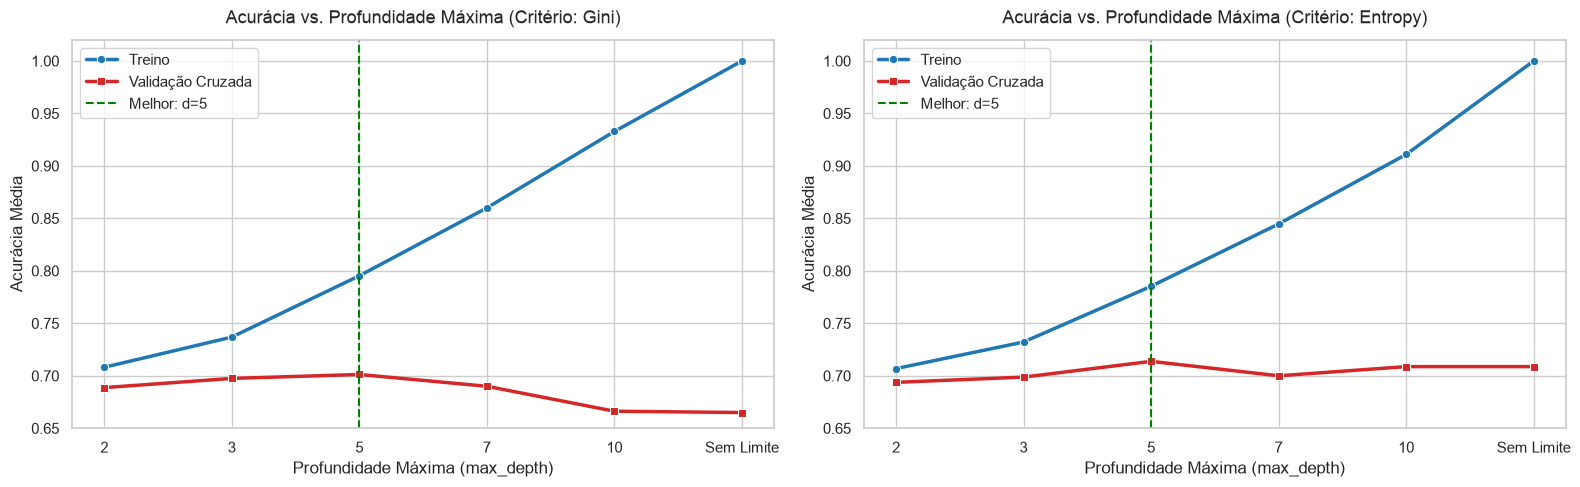

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for i, crit in enumerate(['gini', 'entropy']):
    sub_df = df_tuning[df_tuning['Critério'] == crit]

    sns.lineplot(
        x=depth_labels,
        y=sub_df['Acurácia Treino'],
        marker='o',
        linewidth=2.5,
        color='#1f77b4',
        label='Treino',
        ax=axes[i]
    )
    sns.lineplot(
        x=depth_labels,
        y=sub_df['Acurácia Validação'],
        marker='s',
        linewidth=2.5,
        color='#d62728',
        label='Validação Cruzada',
        ax=axes[i]
    )

    # Destaca o ponto de pico de validação
    best_row = sub_df.loc[sub_df['Acurácia Validação'].idxmax()]
    axes[i].axvline(best_row['Profundidade'], color='green', linestyle='--', linewidth=1.5, label=f"Melhor: d={best_row['Profundidade']}")

    axes[i].set_title(f"Acurácia vs. Profundidade Máxima (Critério: {crit.capitalize()})", fontsize=13, pad=12)
    axes[i].set_xlabel("Profundidade Máxima (max_depth)", fontsize=12)
    axes[i].set_ylabel("Acurácia Média", fontsize=12)
    axes[i].set_ylim([0.65, 1.02])
    axes[i].legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

### Configuração escolhida

| Critério | Melhor profundidade testada | Acurácia média de validação |
|---|---:|---:|
| Gini | 5 | 0,7012 |
| Entropia | **5** | **0,7137** |

Escolhemos **entropia com profundidade 5**. A vantagem sobre Gini foi de cerca de **1,25 ponto percentual**, pequena nesta comparação e sem demonstrar superioridade geral do critério.

### Controle de complexidade

- **Árvores rasas:** poucas regras podem não capturar os padrões da base, levando a subajuste (*underfitting*).
- **Árvores profundas:** a acurácia de treino aumenta, mas a de validação não acompanha, indicando sobreajuste (*overfitting*).

Sem limite, ambas alcançaram **1,0 no treino**. Na validação, ficaram em 0,6650 (Gini) e 0,7088 (entropia), abaixo dos respectivos resultados com profundidade 5.

## Tarefa 5 — Interpretação da árvore

Exibimos a árvore escolhida e a importância das entradas, medida pela redução de impureza. Essas importâncias descrevem o modelo ajustado; não estabelecem efeitos causais.

,Atributo,Importância Relativa
0,checking_status_A14,0.2793
1,credit_amount,0.1845
2,duration,0.0897
3,age,0.0657
4,other_payment_plans_A143,0.0547
5,employment_A74,0.0416
6,purpose_A46,0.0405
7,savings_status_A64,0.0362
8,other_parties_A102,0.0333
9,employment_A72,0.0311


/tmp/ipykernel_70732/2526786893.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


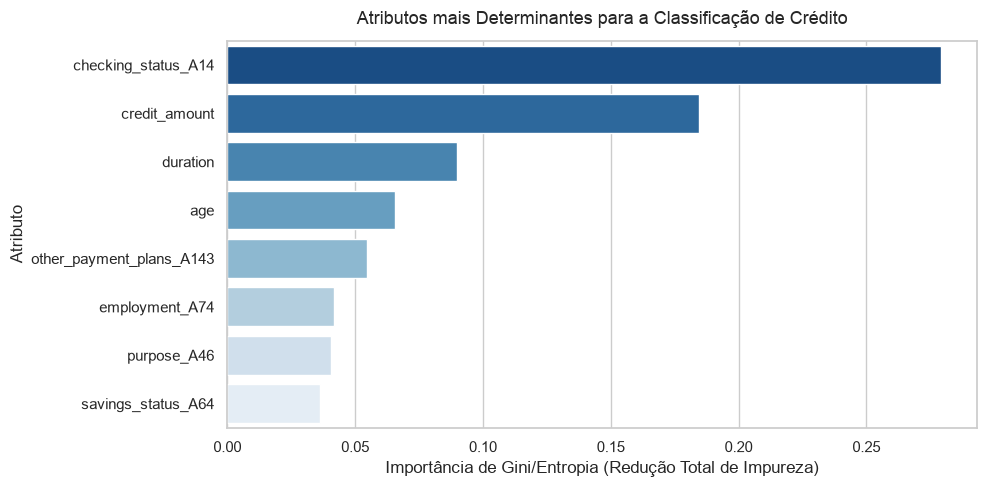

In [9]:
modelo_arvore = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=5,
    random_state=42
)
modelo_arvore.fit(X_train, y_train)

# Importância dos Atributos
importancias = pd.Series(modelo_arvore.feature_importances_, index=X.columns).sort_values(ascending=False)
top_importancias = importancias[importancias > 0]

tabela_imp = pd.DataFrame({
    'Atributo': top_importancias.index,
    'Importância Relativa': top_importancias.values.round(4)
})
display(tabela_imp.head(10))

plt.figure(figsize=(10, 5))
sns.barplot(
    data=tabela_imp.head(8),
    x='Importância Relativa',
    y='Atributo',
    palette='Blues_r'
)
plt.title("Atributos mais Determinantes para a Classificação de Crédito", fontsize=13, pad=12)
plt.xlabel("Importância de Gini/Entropia (Redução Total de Impureza)")
plt.ylabel("Atributo")
plt.tight_layout()
plt.show()

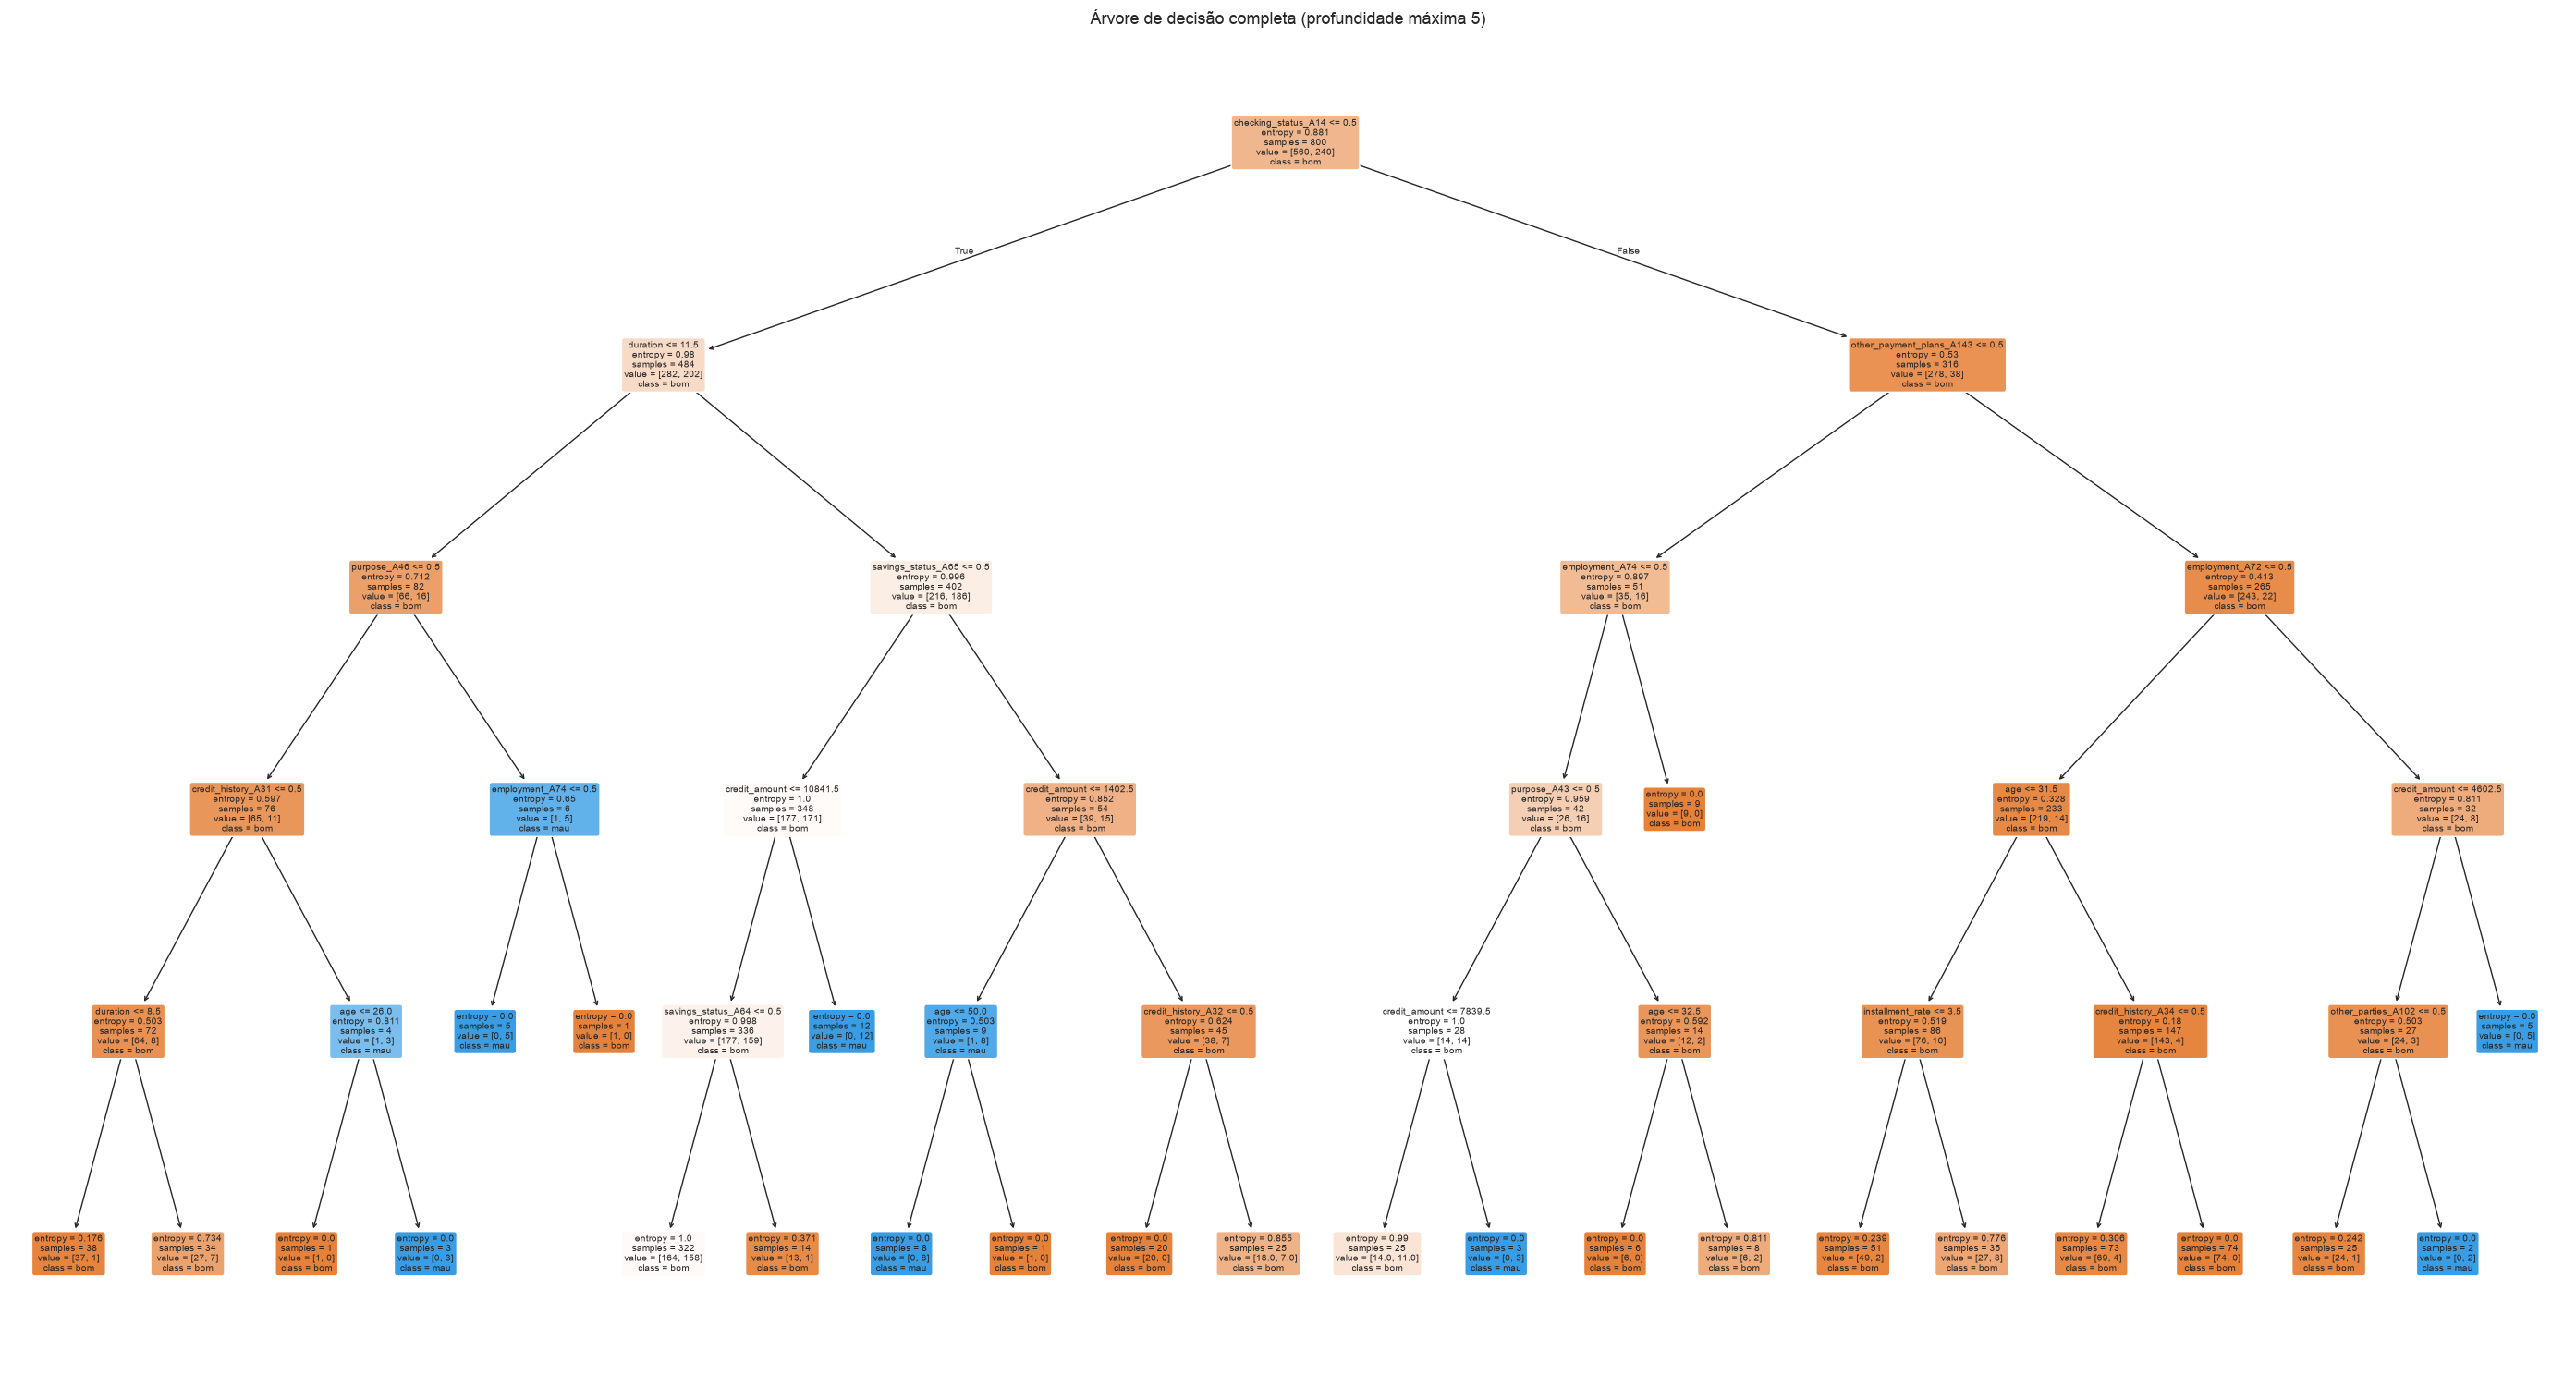

In [10]:
fig, ax = plt.subplots(figsize=(28, 15))
plot_tree(
    modelo_arvore,
    feature_names=list(X.columns),
    class_names=['bom', 'mau'],
    filled=True, rounded=True, fontsize=7, ax=ax
)
plt.title('Árvore de decisão completa (profundidade máxima 5)')
plt.tight_layout()
plt.show()


### Três entradas mais importantes

| Entrada | Significado | Importância |
|---|---|---:|
| `checking_status_A14` | Ausência de conta corrente | 0,2793 |
| `credit_amount` | Valor do crédito | 0,1845 |
| `duration` | Duração do empréstimo | 0,0897 |

### Caminho até a folha com mais casos de mau risco

Essa folha reúne **158 maus e 164 bons riscos** no treino. Todas as condições abaixo precisam ser satisfeitas, na ordem da raiz até a folha:

| Corte | Condição em linguagem natural |
|---|---|
| `checking_status_A14 = 0` | O cliente possui conta corrente. |
| `duration > 11,5` | O prazo solicitado é superior a 11,5 meses. |
| `savings_status_A65 = 0` | O cliente não está na categoria “poupança desconhecida ou inexistente”. |
| `credit_amount ≤ 10.841,5` | O valor solicitado é de até 10.841,5 marcos alemães (DM). |
| `savings_status_A64 = 0` | Excluída também a categoria de pelo menos 1.000 DM, a poupança informada é inferior a 1.000 DM. |

Os significados de A14, A64 e A65 vêm do arquivo `german.doc`.

**A folha prevê bom risco**, pois há ligeiramente mais bons que maus. Ter o maior número absoluto de maus não significa que a folha tenha maioria dessa classe.

## Tarefa 6 — Avaliação e tipos de erro

Avaliamos a árvore no teste e examinamos separadamente os dois tipos de erro. A documentação da base atribui custos diferentes a eles.

In [11]:
y_pred = modelo_arvore.predict(X_test)

print("=== Relatório de Classificação Detalhado (Conjunto de Teste) ===")
print(classification_report(y_test, y_pred, labels=['bom', 'mau'], digits=4))

=== Relatório de Classificação Detalhado (Conjunto de Teste) ===
              precision    recall  f1-score   support

         bom     0.7104    0.9286    0.8050       140
         mau     0.4118    0.1167    0.1818        60

    accuracy                         0.6850       200
   macro avg     0.5611    0.5226    0.4934       200
weighted avg     0.6208    0.6850    0.6180       200



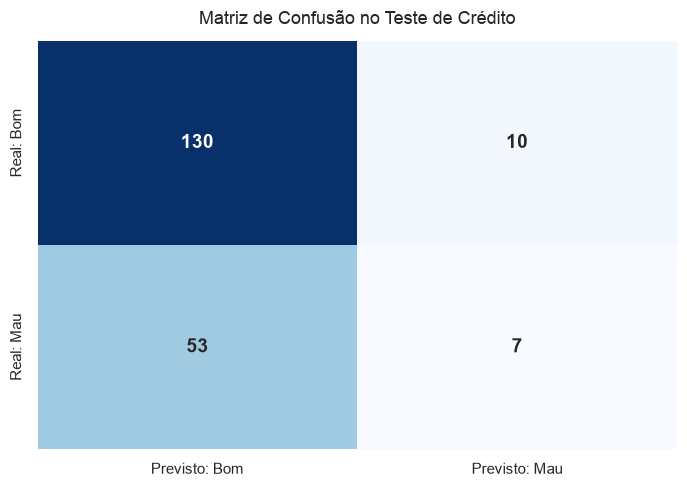

,Previsto: Bom Pagador,Previsto: Mau Pagador
Real: Bom Pagador,130,10
Real: Mau Pagador,53,7


In [12]:
cm = confusion_matrix(y_test, y_pred, labels=['bom', 'mau'])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Previsto: Bom', 'Previsto: Mau'],
    yticklabels=['Real: Bom', 'Real: Mau'],
    cbar=False,
    annot_kws={"size": 14, "weight": "bold"}
)
plt.title("Matriz de Confusão no Teste de Crédito", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

tabela_cm = pd.DataFrame(
    cm,
    index=['Real: Bom Pagador', 'Real: Mau Pagador'],
    columns=['Previsto: Bom Pagador', 'Previsto: Mau Pagador']
)
display(tabela_cm)

### Desempenho no teste

**Acurácia: 0,6850**, abaixo da referência de 0,70 obtida ao prever sempre bom.

| Classe | Precisão | Recall | F1 |
|---|---:|---:|---:|
| Bom risco | 0,7104 | 0,9286 | 0,8050 |
| Mau risco | 0,4118 | 0,1167 | 0,1818 |

### Erro mais frequente e mais custoso

| Erro | Casos | Custo relativo na base |
|---|---:|---:|
| Mau previsto como bom | **53** | **5** |
| Bom previsto como mau | 10 | 1 |

O primeiro erro deixa passar um cliente de mau risco e pode gerar perda do crédito concedido. A matriz de custos de `german.doc` o penaliza cinco vezes mais que o erro inverso.

### Ajuste proposto

Testaríamos `class_weight={'bom': 1, 'mau': 5}` durante o treinamento e escolheríamos a configuração por custo médio na validação.

O objetivo seria reduzir maus previstos como bons, medindo também o aumento de recusas de bons clientes. Esse ajuste é uma proposta; os resultados acima são da árvore sem pesos de classe.

### O que isso significa para a concessão de crédito?

A árvore identifica apenas **7 dos 60 maus riscos (11,7%)** e deixa passar os outros **53 (88,3%)**. Já as dez recusas de bons clientes representam oportunidades de negócio perdidas. Assim, os dois erros importam, mas a penalização da base dá prioridade ao primeiro.

Pela matriz de custos fornecida, o custo total no teste é **53 × 5 + 10 × 1 = 275**, ou **1,375 por solicitação**. Prever sempre bom teria custo 300, ou 1,5 por solicitação: a árvore tem acurácia menor, mas custo ligeiramente menor nesse critério. Esses valores são unidades de penalização, não perdas monetárias.

**Conclusão:** a configuração escolhida por acurácia ainda detecta poucos maus riscos. O ajuste proposto deve ser comparado pelo custo e pelo recall de mau risco na validação, acompanhando também as recusas de bons clientes.
